# Day 15 — Python Environment Management for Data Science

**Data:** 28/10/2026 · **Fase 1 — Python Basics (Dia 15/28)**

### Contexto de aprendizado

Nos últimos dias escrevi testes (Dia 10), tipei código (Dia 13) e paralelizei pipelines (Dia 14). Mas todo esse trabalho só é **reproduzível** se outra pessoa (ou eu mesmo daqui a seis meses) conseguir recriar exatamente o mesmo ambiente. Hoje o foco é **gerenciamento de ambientes e dependências**:

| Ferramenta | Papel principal |
| --- | --- |
| `venv` | Ambientes virtuais leves, da biblioteca padrão |
| `pip` / `pip-tools` | Instalar pacotes do PyPI; "travar" versões (`pip-compile`) |
| `conda` | Ambientes com binários não-Python (CUDA, MKL, GDAL) |
| `uv` | Gerenciador moderno em Rust: venv + pip + lock em uma só ferramenta |
| `pyproject.toml` | Arquivo padrão (PEP 518/621) que descreve o projeto |

**Regra deste notebook:** comandos seguros (criar um `venv` numa pasta temporária, `pip --version`, `pip freeze`) são executados de verdade com `subprocess.run(..., check=False)`. Comandos que instalariam pacotes ou dependem de ferramentas ausentes (`conda`, `uv add`) são apenas **demonstrados** (dry-run). Todos os dados de exemplo vêm de datasets reais do seaborn/scikit-learn ou dos metadados do próprio ambiente.

## 0. Setup e imports

In [1]:
# Standard library only for environment introspection; pandas/seaborn/sklearn for the applied parts.
import json
import platform
import re
import shutil
import subprocess
import sys
import sysconfig
import tempfile
import textwrap
import tomllib
from importlib import metadata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.datasets import load_iris, load_wine
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")

# Every artifact (venvs, requirements files, pyproject) lives in a throwaway directory.
WORKDIR = Path(tempfile.mkdtemp(prefix="day15_env_"))
print(f"Python {platform.python_version()} on {platform.system()} — workdir: {WORKDIR}")

Python 3.13.17 on Linux — workdir: /tmp/day15_env_eo74mbmx


In [2]:
def run(cmd: list[str], execute: bool = True, cwd: Path | None = None, max_lines: int = 12) -> subprocess.CompletedProcess | None:
    # Print a shell command and optionally run it without ever raising (check=False).
    print("$ " + " ".join(cmd))
    if not execute:
        print("   [dry-run] command shown for learning purposes, not executed\n")
        return None
    if shutil.which(cmd[0]) is None and not Path(cmd[0]).exists():
        print(f"   [skipped] '{cmd[0]}' is not installed in this environment\n")
        return None
    result = subprocess.run(cmd, capture_output=True, text=True, check=False, cwd=cwd, timeout=300)
    output = (result.stdout or result.stderr).strip().splitlines()
    for line in output[:max_lines]:
        print("   " + line)
    if len(output) > max_lines:
        print(f"   ... ({len(output) - max_lines} more lines)")
    print(f"   -> exit code {result.returncode}\n")
    return result

_ = run([sys.executable, "--version"])

$ /home/ubuntu/.venvs/nbenv/bin/python --version
   Python 3.13.17
   -> exit code 0



## 1. Por que gerenciar ambientes? O problema das dependências

Sem isolamento, todos os projetos compartilham o mesmo `site-packages`. Isso gera três problemas clássicos:

1. **Conflito de versões** — o projeto A precisa de `pandas<2`, o projeto B de `pandas>=2.2`. Só uma versão cabe no mesmo interpretador.
2. **"Funciona na minha máquina"** — sem uma lista travada (*lock*), outra pessoa instala versões mais novas e o resultado muda (ex.: defaults do scikit-learn mudam entre versões).
3. **Poluição do sistema** — instalar com `sudo pip` pode quebrar ferramentas do sistema operacional que dependem do Python do sistema (por isso a PEP 668 marca o Python do sistema como *externally managed*).

Primeiro, vamos inspecionar **onde** o Python atual procura pacotes e se estamos dentro de um ambiente virtual.

In [3]:
# A venv is detected when sys.prefix differs from sys.base_prefix.
in_venv = sys.prefix != sys.base_prefix
env_info = pd.Series({
    "executable": sys.executable,
    "sys.prefix": sys.prefix,
    "sys.base_prefix": sys.base_prefix,
    "inside virtual env?": in_venv,
    "site-packages (purelib)": sysconfig.get_paths()["purelib"],
    "conda env?": Path(sys.prefix, "conda-meta").exists(),
})
env_info.to_frame("value")

,value
executable,/home/ubuntu/.venvs/nbenv/bin/python
sys.prefix,/home/ubuntu/.venvs/nbenv
sys.base_prefix,/home/ubuntu/.local/share/uv/python/cpython-3.13.17-linux-x86_64-gnu
inside virtual env?,True
site-packages (purelib),/home/ubuntu/.venvs/nbenv/lib/python3.13/site-packages
conda env?,False


### 1.1 O grafo de dependências é maior do que parece

Quando instalo "só" `seaborn`, na verdade instalo uma árvore inteira de dependências transitivas. Uso `importlib.metadata` (biblioteca padrão) para ler os metadados **reais** dos pacotes instalados neste ambiente.

In [4]:
def direct_requirements(dist_name: str) -> list[str]:
    # Return non-optional requirement names declared by an installed distribution.
    reqs = metadata.requires(dist_name) or []
    names = []
    for req in reqs:
        if "extra ==" in req:          # skip optional extras such as [dev] or [stats]
            continue
        names.append(re.split(r"[ ;<>=!~\[(]", req, maxsplit=1)[0].lower().replace("_", "-"))
    return sorted(set(names))

def transitive_closure(root: str) -> set[str]:
    # Walk the dependency graph breadth-first using installed metadata only.
    seen, queue = set(), [root]
    while queue:
        pkg = queue.pop()
        if pkg in seen:
            continue
        seen.add(pkg)
        try:
            queue.extend(direct_requirements(pkg))
        except metadata.PackageNotFoundError:
            pass
    return seen - {root}

for top in ["seaborn", "scikit-learn", "statsmodels"]:
    deps = transitive_closure(top)
    print(f"{top:<13} direct={direct_requirements(top)}\n{'':<13} transitive total={len(deps)} -> {sorted(deps)}\n")

seaborn       direct=['matplotlib', 'numpy', 'pandas']
              transitive total=13 -> ['contourpy', 'cycler', 'fonttools', 'kiwisolver', 'matplotlib', 'numpy', 'packaging', 'pandas', 'pillow', 'pyparsing', 'python-dateutil', 'six', 'tzdata']

scikit-learn  direct=['joblib', 'narwhals', 'numpy', 'scipy', 'threadpoolctl']
              transitive total=6 -> ['cloudpickle', 'joblib', 'narwhals', 'numpy', 'scipy', 'threadpoolctl']

statsmodels   direct=['formulaic', 'numpy', 'packaging', 'pandas', 'patsy', 'scipy']
              transitive total=13 -> ['formulaic', 'interface-meta', 'narwhals', 'numpy', 'packaging', 'pandas', 'patsy', 'python-dateutil', 'scipy', 'six', 'typing-extensions', 'tzdata', 'wrapt']



In [5]:
# Build a DataFrame describing every distribution installed in the current environment.
rows = []
for dist in metadata.distributions():
    name = dist.metadata["Name"]
    if not name:
        continue
    rows.append({
        "package": name.lower(),
        "version": dist.version,
        "n_direct_deps": len([r for r in (dist.requires or []) if "extra ==" not in r]),
    })
installed = pd.DataFrame(rows).drop_duplicates("package").sort_values("n_direct_deps", ascending=False)
print(f"{len(installed)} distributions installed in this environment")
installed.head(10)

118 distributions installed in this environment


,package,version,n_direct_deps
8,jupyter_server,2.21.1,19
54,nbconvert,7.17.2,15
110,jupyterlab,4.6.4,15
19,ipykernel,7.4.0,12
100,ipython,9.17.1,11
113,matplotlib,3.11.2,9
27,formulaic,1.2.2,8
82,jupyter-console,6.6.3,8
74,jupyter-events,0.12.1,8
24,jupyterlab_server,2.28.1,7


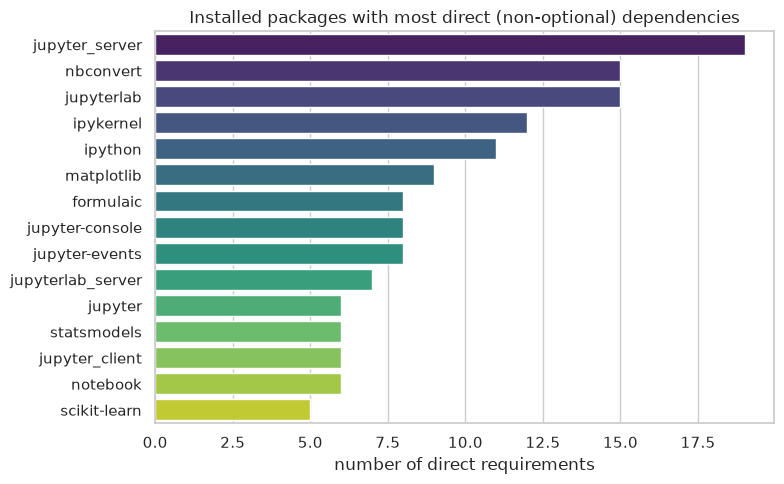

In [6]:
# Visualize which installed packages pull in the most direct dependencies (real environment metadata).
top15 = installed.head(15)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=top15, y="package", x="n_direct_deps", hue="package", palette="viridis", legend=False, ax=ax)
ax.set(title="Installed packages with most direct (non-optional) dependencies",
       xlabel="number of direct requirements", ylabel="")
plt.tight_layout()
plt.show()

**Nota de aprendizado:** o gráfico acima é do *meu* ambiente — em outra máquina os números mudam, e é justamente esse o ponto. Pacotes como `jupyter` ou `statsmodels` arrastam dezenas de dependências; qualquer uma delas pode mudar de versão e alterar resultados. Por isso precisamos **isolar** (venv/conda) e **travar** (lock files).

## 2. `venv`: ambientes virtuais da biblioteca padrão

`venv` cria uma pasta com: um link/cópia do interpretador, um `site-packages` vazio e scripts de ativação. Comandos típicos:

```bash
python -m venv .venv                 # create
source .venv/bin/activate            # activate (Linux/macOS)
.venv\Scripts\activate               # activate (Windows PowerShell/cmd)
python -m pip install pandas seaborn # install inside the venv
deactivate                           # leave the venv
```

"Ativar" apenas coloca `.venv/bin` no início do `PATH`. Em scripts e CI, é mais robusto chamar o executável diretamente: `.venv/bin/python -m pip ...` — é o que faço abaixo, criando um venv **real** na pasta temporária.

In [7]:
venv_dir = WORKDIR / ".venv"
# --without-pip keeps the demo fast and offline; in real projects omit it (pip is bootstrapped via ensurepip).
run([sys.executable, "-m", "venv", "--without-pip", str(venv_dir)])

bin_dir = venv_dir / ("Scripts" if platform.system() == "Windows" else "bin")
venv_python = bin_dir / ("python.exe" if platform.system() == "Windows" else "python")
print("Created files:", sorted(p.name for p in venv_dir.iterdir()))
print("Scripts dir  :", sorted(p.name for p in bin_dir.iterdir()))

$ /home/ubuntu/.venvs/nbenv/bin/python -m venv --without-pip /tmp/day15_env_eo74mbmx/.venv
   -> exit code 0

Created files: ['.gitignore', 'bin', 'include', 'lib', 'lib64', 'pyvenv.cfg']
Scripts dir  : ['Activate.ps1', 'activate', 'activate.csh', 'activate.fish', 'python', 'python3', 'python3.13']


In [8]:
# pyvenv.cfg records which base interpreter the venv points to.
print((venv_dir / "pyvenv.cfg").read_text())

# The new interpreter has an isolated prefix and an (almost) empty site-packages.
probe = "import sys, sysconfig; print(sys.prefix != sys.base_prefix); print(sysconfig.get_paths()['purelib'])"
_ = run([str(venv_python), "-c", probe])

home = /home/ubuntu/.local/share/uv/python/cpython-3.13-linux-x86_64-gnu/bin
include-system-site-packages = false
version = 3.13.17
executable = /home/ubuntu/.local/share/uv/python/cpython-3.13.17-linux-x86_64-gnu/bin/python3.13
command = /home/ubuntu/.venvs/nbenv/bin/python -m venv --without-pip /tmp/day15_env_eo74mbmx/.venv

$ /tmp/day15_env_eo74mbmx/.venv/bin/python -c import sys, sysconfig; print(sys.prefix != sys.base_prefix); print(sysconfig.get_paths()['purelib'])
   True
   /tmp/day15_env_eo74mbmx/.venv/lib/python3.13/site-packages
   -> exit code 0



In [9]:
# Compare what is importable inside the new venv vs. the current kernel.
check = "import importlib.util as u; print({m: u.find_spec(m) is not None for m in ['pandas', 'seaborn', 'sklearn', 'json']})"
print("Inside the fresh venv:")
run([str(venv_python), "-c", check])
print("Inside the notebook kernel:")
_ = run([sys.executable, "-c", check])

Inside the fresh venv:
$ /tmp/day15_env_eo74mbmx/.venv/bin/python -c import importlib.util as u; print({m: u.find_spec(m) is not None for m in ['pandas', 'seaborn', 'sklearn', 'json']})
   {'pandas': False, 'seaborn': False, 'sklearn': False, 'json': True}
   -> exit code 0

Inside the notebook kernel:
$ /home/ubuntu/.venvs/nbenv/bin/python -c import importlib.util as u; print({m: u.find_spec(m) is not None for m in ['pandas', 'seaborn', 'sklearn', 'json']})
   {'pandas': True, 'seaborn': True, 'sklearn': True, 'json': True}
   -> exit code 0



**Nota de aprendizado:** o venv recém-criado só enxerga a biblioteca padrão (`json` → `True`), mas **não** `pandas`/`seaborn`/`sklearn`. Isso é o isolamento funcionando. Detalhe importante: o venv **não é portátil** — ele guarda caminhos absolutos. Nunca se versiona a pasta `.venv/`; versiona-se a **receita** (`requirements.txt`, `pyproject.toml`, lock file).

## 3. `pip`: comandos essenciais

| Comando | O que faz |
| --- | --- |
| `pip install pkg==1.2.3` | instala versão exata |
| `pip install -r requirements.txt` | instala a partir de um arquivo |
| `pip install -e .` | instalação *editable* do projeto local (usa `pyproject.toml`) |
| `pip list --outdated` | mostra pacotes com versões novas |
| `pip show pkg` | metadados e dependências de um pacote |
| `pip freeze > requirements.txt` | "fotografa" todas as versões instaladas |
| `pip check` | verifica se há dependências incompatíveis |
| `pip uninstall pkg` | remove (mas **não** remove dependências órfãs) |

Sempre prefira `python -m pip` em vez de `pip` puro: garante que o pip usado pertence ao interpretador certo.

In [10]:
run([sys.executable, "-m", "pip", "--version"])
_ = run([sys.executable, "-m", "pip", "show", "seaborn"], max_lines=11)

$ /home/ubuntu/.venvs/nbenv/bin/python -m pip --version


   pip 26.2.2 from /home/ubuntu/.venvs/nbenv/lib/python3.13/site-packages/pip (python 3.13)
   -> exit code 0

$ /home/ubuntu/.venvs/nbenv/bin/python -m pip show seaborn


   Name: seaborn
   Version: 0.13.2
   Summary: Statistical data visualization
   Home-page: 
   Author: 
   Author-email: Michael Waskom <mwaskom@gmail.com>
   License: 
   Location: /home/ubuntu/.venvs/nbenv/lib/python3.13/site-packages
   Requires: matplotlib, numpy, pandas
   Required-by:
   -> exit code 0



In [11]:
# pip check validates that installed packages have compatible requirements (exit code 0 = OK).
run([sys.executable, "-m", "pip", "check"])

# Commands that would modify the environment are shown, not executed.
run([sys.executable, "-m", "pip", "install", "--upgrade", "pandas"], execute=False)
_ = run([sys.executable, "-m", "pip", "list", "--outdated"], execute=False)

$ /home/ubuntu/.venvs/nbenv/bin/python -m pip check


   No broken requirements found.
   -> exit code 0

$ /home/ubuntu/.venvs/nbenv/bin/python -m pip install --upgrade pandas
   [dry-run] command shown for learning purposes, not executed

$ /home/ubuntu/.venvs/nbenv/bin/python -m pip list --outdated
   [dry-run] command shown for learning purposes, not executed



### 3.1 `pip freeze` vs. requirements "abstratos"

`pip freeze` lista **tudo** que está instalado (incluindo dependências transitivas e ferramentas como `jupyter`). É ótimo como *snapshot*, mas ruim como lista de intenção: mistura o que eu pedi com o que veio "de carona". A boa prática é separar:

- **`requirements.in`** (ou `[project.dependencies]`): dependências **diretas**, com faixas de versão (`pandas>=2.2,<4`).
- **`requirements.txt` / lock**: resolução **completa e exata** gerada por uma ferramenta (`pip-compile`, `uv pip compile`, `uv lock`).

In [12]:
# Generate a freeze-style snapshot from metadata (equivalent to `pip freeze`, but without spawning pip).
freeze_lines = sorted(f"{r.package}=={r.version}" for r in installed.itertuples())
print(f"Total pinned lines: {len(freeze_lines)}")
print("\n".join(freeze_lines[:8]), "\n...")

direct = {"pandas", "seaborn", "scikit-learn", "statsmodels", "matplotlib"}
transitive_only = [line for line in freeze_lines if line.split("==")[0] not in direct]
print(f"\nDirect deps I actually asked for: {len(direct)} | lines that came along: {len(transitive_only)}")

Total pinned lines: 118
anyio==4.15.1
argon2-cffi-bindings==26.1.0
argon2-cffi==25.1.0
arrow==1.4.0
asttokens==3.0.2
async-lru==2.4.0
attrs==26.1.0
babel==2.18.0 
...

Direct deps I actually asked for: 5 | lines that came along: 113


### 3.2 `pip-tools`: `pip-compile` e `pip-sync`

`pip-tools` resolve o problema acima com dois comandos:

```bash
pip install pip-tools
pip-compile requirements.in -o requirements.txt      # resolve + pin everything, with comments "# via ..."
pip-compile --extra dev pyproject.toml -o requirements-dev.txt
pip-sync requirements.txt requirements-dev.txt       # make the venv match the files exactly (removes extras)
```

Abaixo escrevo um `requirements.in` real e mostro os comandos (sem executá-los, para não instalar nada).

In [13]:
requirements_in = textwrap.dedent('''
    # Direct dependencies only, with compatible ranges
    pandas>=2.2,<4
    seaborn>=0.13
    scikit-learn>=1.5
    statsmodels>=0.14
''').lstrip()
(WORKDIR / "requirements.in").write_text(requirements_in)
print(requirements_in)

run(["pip-compile", "--generate-hashes", "requirements.in", "-o", "requirements.txt"], execute=False, cwd=WORKDIR)
_ = run(["pip-sync", "requirements.txt"], execute=False, cwd=WORKDIR)

# Direct dependencies only, with compatible ranges
pandas>=2.2,<4
seaborn>=0.13
scikit-learn>=1.5
statsmodels>=0.14

$ pip-compile --generate-hashes requirements.in -o requirements.txt
   [dry-run] command shown for learning purposes, not executed

$ pip-sync requirements.txt
   [dry-run] command shown for learning purposes, not executed



## 4. `conda`: ambientes com dependências não-Python

`conda` (Anaconda/Miniconda/Miniforge) gerencia **pacotes binários de qualquer linguagem** — não só Python. Isso importa em DS quando preciso de CUDA, MKL, GDAL/PROJ (geoespacial) ou R. Comandos típicos:

```bash
conda create -n nlp-edu python=3.12 pandas scikit-learn -c conda-forge
conda activate nlp-edu
conda install -c conda-forge spacy
conda env export --from-history > environment.yml   # only what I explicitly asked for
conda env create -f environment.yml
conda env remove -n nlp-edu
```

**Diferenças em relação a `venv`:**

| Aspecto | `venv` + `pip` | `conda` |
| --- | --- | --- |
| Fonte de pacotes | PyPI (wheels) | canais conda (`conda-forge`, `defaults`) |
| Gerencia o próprio Python? | Não (usa um Python já instalado) | Sim (`python=3.12` é só mais um pacote) |
| Bibliotecas C/C++/CUDA | Só se vierem dentro do wheel | Sim, como pacotes de primeira classe |
| Onde fica o ambiente | Pasta do projeto (`.venv/`) | Diretório central (`~/miniconda3/envs/`) |
| Arquivo de receita | `requirements.txt` / `pyproject.toml` | `environment.yml` |

Dica: misturar `conda install` e `pip install` no mesmo ambiente é possível, mas instale primeiro tudo via conda e só depois o que faltar via pip (seção `pip:` do `environment.yml`). Atenção também à licença do canal `defaults` da Anaconda para uso comercial — `conda-forge`/Miniforge evitam esse problema.

In [14]:
environment_yml = textwrap.dedent('''
    name: nlp-edu
    channels:
      - conda-forge
    dependencies:
      - python=3.12
      - pandas>=2.2
      - scikit-learn>=1.5
      - seaborn>=0.13
      - statsmodels>=0.14
      - nltk>=3.9
      - pip
      - pip:
          - textstat>=0.7   # PyPI-only package goes in the pip section
''').lstrip()
(WORKDIR / "environment.yml").write_text(environment_yml)
print(environment_yml)

# conda is usually not available in CI containers; the helper skips gracefully.
conda_exe = shutil.which("conda") or shutil.which("mamba") or shutil.which("micromamba")
print("conda-like executable found:", conda_exe)
run(["conda", "env", "create", "-f", "environment.yml"], execute=False, cwd=WORKDIR)
_ = run(["conda", "--version"], execute=conda_exe is not None)

name: nlp-edu
channels:
  - conda-forge
dependencies:
  - python=3.12
  - pandas>=2.2
  - scikit-learn>=1.5
  - seaborn>=0.13
  - statsmodels>=0.14
  - nltk>=3.9
  - pip
  - pip:
      - textstat>=0.7   # PyPI-only package goes in the pip section

conda-like executable found: None
$ conda env create -f environment.yml
   [dry-run] command shown for learning purposes, not executed

$ conda --version
   [dry-run] command shown for learning purposes, not executed



## 5. `uv`: o gerenciador moderno (Astral, escrito em Rust)

Em 2025 o `uv` se tornou a escolha padrão em muitos projetos novos. Ele substitui `pip`, `pip-tools`, `virtualenv`, `pyenv` e parte do `poetry`, sendo 10–100× mais rápido graças a cache global e resolução em Rust.

```bash
curl -LsSf https://astral.sh/uv/install.sh | sh   # or: pipx install uv / brew install uv
uv python install 3.13                            # manage interpreters too
uv venv                                           # create .venv
uv pip install -r requirements.txt                # pip-compatible interface
uv pip compile requirements.in -o requirements.txt

# Project workflow (pyproject.toml + uv.lock):
uv init nlp-edu && cd nlp-edu
uv add pandas scikit-learn seaborn                # updates pyproject.toml AND uv.lock
uv add --dev pytest ruff mypy                     # dev dependency group
uv sync                                           # make .venv match uv.lock exactly
uv run python analysis.py                         # run inside the project env (no activation)
uv lock --upgrade-package pandas                  # controlled upgrade
```

O `uv.lock` é **multiplataforma**: um único arquivo descreve a resolução para Linux, macOS e Windows. Abaixo, executo de verdade apenas comandos que não acessam a rede (versão e criação de venv), se o `uv` estiver instalado.

In [15]:
uv_exe = shutil.which("uv")
print("uv found:", uv_exe)
run(["uv", "--version"], execute=uv_exe is not None)

uv_venv = WORKDIR / ".venv-uv"
# --python points uv at the current interpreter, so no download is needed.
run(["uv", "venv", "--quiet", "--python", sys.executable, str(uv_venv)], execute=uv_exe is not None)
print("uv venv created:", (uv_venv / "pyvenv.cfg").exists())

uv found: /usr/local/bin/uv
$ uv --version
   uv 0.13.5 (x86_64-unknown-linux-gnu)
   -> exit code 0

$ uv venv --quiet --python /home/ubuntu/.venvs/nbenv/bin/python /tmp/day15_env_eo74mbmx/.venv-uv
   -> exit code 0

uv venv created: True


In [16]:
# Network-dependent / project-mutating uv commands are demonstrated only.
for cmd in (["uv", "init", "nlp-edu"],
            ["uv", "add", "pandas", "scikit-learn", "seaborn"],
            ["uv", "add", "--dev", "pytest", "ruff"],
            ["uv", "lock"],
            ["uv", "sync", "--frozen"],
            ["uv", "pip", "compile", "requirements.in", "-o", "requirements.txt"]):
    run(cmd, execute=False)

$ uv init nlp-edu
   [dry-run] command shown for learning purposes, not executed

$ uv add pandas scikit-learn seaborn
   [dry-run] command shown for learning purposes, not executed

$ uv add --dev pytest ruff
   [dry-run] command shown for learning purposes, not executed

$ uv lock
   [dry-run] command shown for learning purposes, not executed

$ uv sync --frozen
   [dry-run] command shown for learning purposes, not executed

$ uv pip compile requirements.in -o requirements.txt
   [dry-run] command shown for learning purposes, not executed



### 5.1 Como é um `uv.lock`?

O lock é um TOML gerado automaticamente — **nunca** se edita à mão, mas **sempre** se versiona no Git. Trecho representativo da estrutura (formato simplificado; hashes abreviados):

```toml
version = 1
requires-python = ">=3.11"

[[package]]
name = "pandas"
version = "2.2.3"
source = { registry = "https://pypi.org/simple" }
dependencies = [
    { name = "numpy" },
    { name = "python-dateutil" },
    { name = "pytz" },
    { name = "tzdata" },
]
wheels = [{ url = "https://files.pythonhosted.org/...", hash = "sha256:..." }]
```

Como é TOML, posso lê-lo com `tomllib` (stdlib desde o Python 3.11) — faço isso com o `pyproject.toml` na próxima seção.

## 6. `pyproject.toml`: a estrutura moderna de projetos

Definido pelas PEPs 518 (build system), 621 (metadados do projeto) e 735 (*dependency groups*), o `pyproject.toml` centraliza **tudo** num só arquivo: metadados, dependências, extras opcionais, grupos de dev e configuração de ferramentas (`ruff`, `pytest`, `mypy`). Substitui `setup.py`, `setup.cfg` e boa parte dos arquivos `requirements*.txt`.

In [17]:
pyproject_toml = textwrap.dedent('''
    [project]
    name = "edu-text-analytics"
    version = "0.1.0"
    description = "Readability and vocabulary profiling for English-language teaching materials"
    readme = "README.md"
    requires-python = ">=3.11"
    authors = [{ name = "Gutemberg Raposo", email = "gtmbrgfox@gmail.com" }]
    dependencies = [
        "pandas>=2.2,<4",
        "scikit-learn>=1.5",
        "seaborn>=0.13",
        "nltk>=3.9",
    ]

    [project.optional-dependencies]
    stats = ["statsmodels>=0.14"]
    transformers = ["transformers>=4.45", "torch>=2.4"]

    [dependency-groups]
    dev = ["pytest>=8", "pytest-cov>=5", "ruff>=0.6", "mypy>=1.11"]
    notebooks = ["jupyterlab>=4", "nbconvert>=7"]

    [build-system]
    requires = ["hatchling"]
    build-backend = "hatchling.build"

    [tool.ruff]
    line-length = 100
    target-version = "py311"

    [tool.pytest.ini_options]
    testpaths = ["tests"]
    addopts = "-q --cov=edu_text_analytics"
''').lstrip()
(WORKDIR / "pyproject.toml").write_text(pyproject_toml)

config = tomllib.loads(pyproject_toml)
print("Sections:", list(config))
print("Runtime deps:", config["project"]["dependencies"])
print("Extras:", list(config["project"]["optional-dependencies"]))
print("Dev groups:", {k: len(v) for k, v in config["dependency-groups"].items()})

Sections: ['project', 'dependency-groups', 'build-system', 'tool']
Runtime deps: ['pandas>=2.2,<4', 'scikit-learn>=1.5', 'seaborn>=0.13', 'nltk>=3.9']
Extras: ['stats', 'transformers']
Dev groups: {'dev': 4, 'notebooks': 2}


In [18]:
# Turn every declared requirement into a tidy table: where it is declared and how it is constrained.
REQ_RE = re.compile(r"^(?P<name>[A-Za-z0-9_.\-]+)\s*(?P<spec>.*)$")

def parse_requirement(req: str) -> dict:
    m = REQ_RE.match(req.strip())
    return {"package": m["name"].lower(), "specifier": m["spec"] or "(any)"}

records = [{"section": "project.dependencies", **parse_requirement(r)} for r in config["project"]["dependencies"]]
for extra, reqs in config["project"]["optional-dependencies"].items():
    records += [{"section": f"extra: {extra}", **parse_requirement(r)} for r in reqs]
for group, reqs in config["dependency-groups"].items():
    records += [{"section": f"group: {group}", **parse_requirement(r)} for r in reqs]

declared = pd.DataFrame(records)
declared["has_upper_bound"] = declared["specifier"].str.contains("<")
declared

,section,package,specifier,has_upper_bound
0,project.dependencies,pandas,">=2.2,<4",True
1,project.dependencies,scikit-learn,>=1.5,False
2,project.dependencies,seaborn,>=0.13,False
3,project.dependencies,nltk,>=3.9,False
4,extra: stats,statsmodels,>=0.14,False
5,extra: transformers,transformers,>=4.45,False
6,extra: transformers,torch,>=2.4,False
7,group: dev,pytest,>=8,False
8,group: dev,pytest-cov,>=5,False
9,group: dev,ruff,>=0.6,False


**Nota de aprendizado:** a diferença entre *extras* e *dependency groups* confundiu-me no começo:

- **`[project.optional-dependencies]` (extras):** fazem parte do pacote publicado; o usuário final instala com `pip install edu-text-analytics[stats]`.
- **`[dependency-groups]` (PEP 735):** só existem para quem desenvolve o projeto (testes, lint, notebooks); **não** são publicados. `uv sync --group dev` ou `pip install --group dev` (pip ≥ 25.1).

Em bibliotecas, use faixas de versão amplas no `pyproject.toml` (não "trave" o usuário). Em **aplicações/análises**, a reprodutibilidade vem do **lock file**.

## 7. Boas práticas

1. **Um ambiente por projeto**, dentro da pasta do projeto (`.venv/`), nunca versionado.
2. **Separar dependências de produção e de desenvolvimento** (`requirements.txt` vs `requirements-dev.txt`, ou `[dependency-groups]`).
3. **Versionar a receita e o lock**: `pyproject.toml` + `uv.lock` (ou `requirements.in` + `requirements.txt` gerado).
4. **Fixar a versão do Python** (`requires-python`, `.python-version`).
5. **Registrar o ambiente junto com os resultados** de experimentos (versões de `sklearn`, `numpy`...).
6. **Atualizar deliberadamente** (`uv lock --upgrade-package X`, Dependabot/Renovate) e rodar os testes depois.
7. **Nunca usar `sudo pip install`** no Python do sistema.

In [19]:
gitignore = textwrap.dedent('''
    # --- Virtual environments (recreate them from the recipe, never commit) ---
    .venv/
    .venv-uv/
    venv/
    env/
    .conda/
    # --- Python caches / build artifacts ---
    __pycache__/
    *.py[cod]
    *.egg-info/
    build/
    dist/
    .pytest_cache/
    .mypy_cache/
    .ruff_cache/
    .coverage
    # --- Notebooks & secrets ---
    .ipynb_checkpoints/
    .env
    # NOTE: do NOT ignore uv.lock, requirements*.txt, environment.yml or pyproject.toml
''').lstrip()
(WORKDIR / ".gitignore").write_text(gitignore)

# Verify the rules against the artifacts created in this notebook (simple prefix match on directory rules).
ignored_dirs = {line.rstrip("/") for line in gitignore.splitlines() if line.endswith("/")}
for item in sorted(WORKDIR.iterdir()):
    status = "IGNORED" if item.name in ignored_dirs else "tracked"
    print(f"{status:<8} {item.name}")

tracked  .gitignore
IGNORED  .venv
IGNORED  .venv-uv
tracked  environment.yml
tracked  pyproject.toml
tracked  requirements.in


In [20]:
# Split production vs. development dependencies into two files; dev includes prod via "-r".
requirements_prod = "\n".join(config["project"]["dependencies"]) + "\n"
requirements_dev = "-r requirements.txt\n" + "\n".join(config["dependency-groups"]["dev"]) + "\n"
(WORKDIR / "requirements.txt").write_text(requirements_prod)
(WORKDIR / "requirements-dev.txt").write_text(requirements_dev)
print("requirements.txt\n----------------\n" + requirements_prod)
print("requirements-dev.txt\n--------------------\n" + requirements_dev)

requirements.txt
----------------
pandas>=2.2,<4
scikit-learn>=1.5
seaborn>=0.13
nltk>=3.9

requirements-dev.txt
--------------------
-r requirements.txt
pytest>=8
pytest-cov>=5
ruff>=0.6
mypy>=1.11



## 8. Aplicação prática: um ambiente DS reproduzível

Vou "travar" o ambiente **real** deste kernel para as bibliotecas que o projeto usa e, em seguida, rodar um experimento com dados reais (`load_wine` do scikit-learn) registrando um **fingerprint** do ambiente junto com o resultado. É assim que um resultado de notebook vira algo auditável.

In [21]:
def pinned_requirements(packages: list[str]) -> list[str]:
    # Pin each package to the version actually installed in the running interpreter.
    lines = []
    for pkg in packages:
        try:
            lines.append(f"{pkg}=={metadata.version(pkg)}")
        except metadata.PackageNotFoundError:
            lines.append(f"# {pkg} not installed here")
    return lines

core = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn", "statsmodels"]
locked = pinned_requirements(core)
lock_text = "# Exact versions captured from the running kernel\n" + "\n".join(locked) + "\n"
(WORKDIR / "requirements-lock.txt").write_text(lock_text)
print(lock_text)

# Exact versions captured from the running kernel
numpy==2.5.4
pandas==3.1.0
scipy==1.18.1
scikit-learn==1.9.1
matplotlib==3.11.2
seaborn==0.13.2
statsmodels==0.15.0



In [22]:
# Verify: does the running environment satisfy the lock file? (a mini `pip check` for our own pins)
def verify_lock(path: Path) -> pd.DataFrame:
    out = []
    for line in path.read_text().splitlines():
        if not line or line.startswith("#"):
            continue
        name, wanted = line.split("==")
        try:
            found = metadata.version(name)
        except metadata.PackageNotFoundError:
            found = None
        out.append({"package": name, "locked": wanted, "installed": found, "ok": found == wanted})
    return pd.DataFrame(out)

lock_report = verify_lock(WORKDIR / "requirements-lock.txt")
assert lock_report["ok"].all(), "environment drifted from the lock file"
lock_report

,package,locked,installed,ok
0,numpy,2.5.4,2.5.4,True
1,pandas,3.1.0,3.1.0,True
2,scipy,1.18.1,1.18.1,True
3,scikit-learn,1.9.1,1.9.1,True
4,matplotlib,3.11.2,3.11.2,True
5,seaborn,0.13.2,0.13.2,True
6,statsmodels,0.15.0,0.15.0,True


In [23]:
# Real experiment on the scikit-learn wine dataset, stored together with an environment fingerprint.
X, y = load_wine(return_X_y=True)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
scores = cross_val_score(model, X, y, cv=5)

run_record = {
    "dataset": "sklearn.datasets.load_wine",
    "n_samples": int(X.shape[0]),
    "cv_accuracy_mean": round(float(scores.mean()), 4),
    "cv_accuracy_std": round(float(scores.std()), 4),
    "environment": {
        "python": platform.python_version(),
        "platform": platform.platform(terse=True),
        **{pkg: metadata.version(pkg) for pkg in ["numpy", "pandas", "scikit-learn"]},
    },
}
(WORKDIR / "run_record.json").write_text(json.dumps(run_record, indent=2))
print(json.dumps(run_record, indent=2))

{
  "dataset": "sklearn.datasets.load_wine",
  "n_samples": 178,
  "cv_accuracy_mean": 0.9832,
  "cv_accuracy_std": 0.0137,
  "environment": {
    "python": "3.13.17",
    "platform": "Linux-6.17.0-1010-aws-x86_64-with-glibc2.36",
    "numpy": "2.5.4",
    "pandas": "3.1.0",
    "scikit-learn": "1.9.1"
  }
}


**Nota de aprendizado:** a acurácia acima só é comparável com outra execução se o bloco `environment` for compatível. Mudanças de versão do scikit-learn já alteraram *defaults* (ex.: `solver` da `LogisticRegression` mudou para `lbfgs` na 0.22). Guardar versões junto com métricas é um hábito barato que evita horas de investigação.

### 8.1 O ambiente realmente afeta os dados? Um exemplo com seaborn

Os datasets de `seaborn.load_dataset()` são baixados do repositório `seaborn-data` e ficam em cache local. Uso o `penguins` para mostrar que até o *dtype* das colunas depende de versões (por exemplo, o pandas 3.x passou a inferir colunas de texto como dtype `str` por padrão, enquanto o pandas 2.x usava `object`).

In [24]:
penguins = sns.load_dataset("penguins")
dtype_report = pd.DataFrame({
    "dtype": penguins.dtypes.astype(str),
    "n_missing": penguins.isna().sum(),
})
print(f"penguins shape={penguins.shape} | pandas {pd.__version__} | seaborn {sns.__version__}")
dtype_report

penguins shape=(344, 7) | pandas 3.1.0 | seaborn 0.13.2


,dtype,n_missing
species,str,0
island,str,0
bill_length_mm,float64,2
bill_depth_mm,float64,2
flipper_length_mm,float64,2
body_mass_g,float64,2
sex,str,11


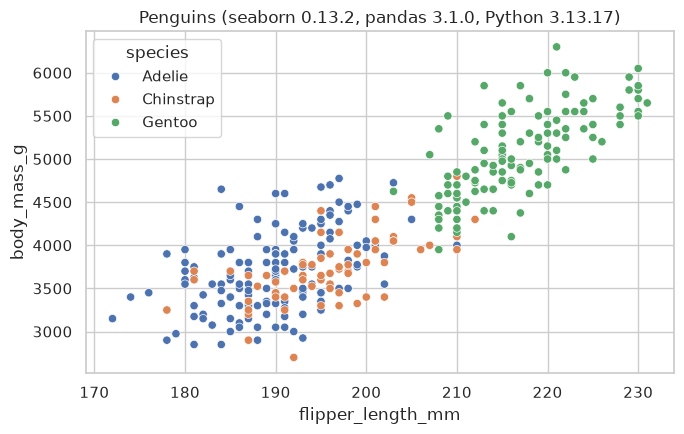

In [25]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g", hue="species", ax=ax)
ax.set_title(f"Penguins (seaborn {sns.__version__}, pandas {pd.__version__}, Python {platform.python_version()})")
plt.tight_layout()
plt.show()

## 9. Comparação das ferramentas (tabela pandas)

Resumo das características que pesquisei para cada ferramenta (informação qualitativa, baseada na documentação oficial de cada projeto em 2025–2026).

In [26]:
comparison = pd.DataFrame([
    {"tool": "venv",     "ships_with_python": True,  "manages_python_versions": False, "non_python_binaries": False,
     "lock_file": "—",                         "recipe_file": "requirements.txt",      "speed": "n/a (no resolver)", "best_for": "simple scripts, teaching, CI"},
    {"tool": "pip",      "ships_with_python": True,  "manages_python_versions": False, "non_python_binaries": False,
     "lock_file": "pip freeze (snapshot)",     "recipe_file": "requirements.txt",      "speed": "baseline",          "best_for": "installing from PyPI"},
    {"tool": "pip-tools","ships_with_python": False, "manages_python_versions": False, "non_python_binaries": False,
     "lock_file": "requirements.txt (compiled)","recipe_file": "requirements.in",      "speed": "baseline",          "best_for": "pinning on top of pip/venv"},
    {"tool": "conda",    "ships_with_python": False, "manages_python_versions": True,  "non_python_binaries": True,
     "lock_file": "conda-lock (external)",     "recipe_file": "environment.yml",       "speed": "slow→ok (libmamba)", "best_for": "CUDA/GDAL/R, scientific stacks"},
    {"tool": "uv",       "ships_with_python": False, "manages_python_versions": True,  "non_python_binaries": False,
     "lock_file": "uv.lock (cross-platform)",  "recipe_file": "pyproject.toml",        "speed": "10-100x pip",        "best_for": "modern projects, apps, CI"},
    {"tool": "poetry",   "ships_with_python": False, "manages_python_versions": False, "non_python_binaries": False,
     "lock_file": "poetry.lock",               "recipe_file": "pyproject.toml",        "speed": "slower than uv",     "best_for": "library packaging/publishing"},
]).set_index("tool")
comparison

,ships_with_python,manages_python_versions,non_python_binaries,lock_file,recipe_file,speed,best_for
tool,,,,,,,
venv,True,False,False,—,requirements.txt,n/a (no resolver),"simple scripts, teaching, CI"
pip,True,False,False,pip freeze (snapshot),requirements.txt,baseline,installing from PyPI
pip-tools,False,False,False,requirements.txt (compiled),requirements.in,baseline,pinning on top of pip/venv
conda,False,True,True,conda-lock (external),environment.yml,slow→ok (libmamba),"CUDA/GDAL/R, scientific stacks"
uv,False,True,False,uv.lock (cross-platform),pyproject.toml,10-100x pip,"modern projects, apps, CI"
poetry,False,False,False,poetry.lock,pyproject.toml,slower than uv,library packaging/publishing


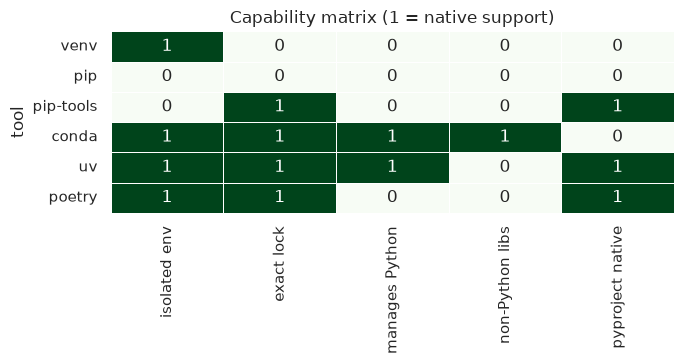

In [27]:
# Score each tool on a few yes/no capabilities to make the trade-offs explicit.
capabilities = pd.DataFrame({
    "isolated env": [1, 0, 0, 1, 1, 1],
    "exact lock": [0, 0, 1, 1, 1, 1],
    "manages Python": comparison["manages_python_versions"].astype(int).tolist(),
    "non-Python libs": comparison["non_python_binaries"].astype(int).tolist(),
    "pyproject native": [0, 0, 1, 0, 1, 1],
}, index=comparison.index)

fig, ax = plt.subplots(figsize=(7, 3.8))
sns.heatmap(capabilities, annot=True, cbar=False, cmap="Greens", linewidths=0.5, ax=ax)
ax.set_title("Capability matrix (1 = native support)")
plt.tight_layout()
plt.show()

**Minha regra de decisão (por enquanto):**

- Projeto novo, só pacotes PyPI → **`uv`** (`pyproject.toml` + `uv.lock`).
- Preciso de CUDA/GDAL/R ou bibliotecas C difíceis → **`conda`/Miniforge** (ou `pixi`).
- Script rápido, aula, ambiente restrito → **`venv` + `pip`** com `requirements.txt` fixado.
- Repositório legado com `requirements.txt` → `uv pip compile`/`pip-tools` sem mudar o fluxo do time.

## 10. Exemplo aplicado: NLP para educação

Cenário: um projeto de análise de textos didáticos de inglês (legibilidade, perfil de vocabulário, classificação por tema). Abaixo está um `requirements.txt` organizado por finalidade, com comentários explicando **por que** cada pacote está lá — algo que facilita muito a revisão por outras pessoas.

In [28]:
edu_nlp_requirements = textwrap.dedent('''
    # edu-text-analytics — runtime dependencies (Python >=3.11)
    # Generate the exact lock with: uv pip compile requirements.in -o requirements.txt

    # --- Data handling ---
    pandas>=2.2,<4          # tabular corpora, per-text metrics
    numpy>=1.26             # vectorized statistics

    # --- Classical NLP ---
    nltk>=3.9               # tokenization, stopwords, Brown/Gutenberg corpora
    spacy>=3.7,<4           # lemmatization and POS tags for lexical profiles
    textstat>=0.7           # Flesch-Kincaid & other readability formulas

    # --- Modelling & evaluation ---
    scikit-learn>=1.5       # TF-IDF, classifiers, cross-validation
    statsmodels>=0.14       # regression of readability vs. learner variables

    # --- Visualization ---
    matplotlib>=3.8
    seaborn>=0.13
''').lstrip()
(WORKDIR / "requirements-edu-nlp.txt").write_text(edu_nlp_requirements)
print(edu_nlp_requirements)

# edu-text-analytics — runtime dependencies (Python >=3.11)
# Generate the exact lock with: uv pip compile requirements.in -o requirements.txt

# --- Data handling ---
pandas>=2.2,<4          # tabular corpora, per-text metrics
numpy>=1.26             # vectorized statistics

# --- Classical NLP ---
nltk>=3.9               # tokenization, stopwords, Brown/Gutenberg corpora
spacy>=3.7,<4           # lemmatization and POS tags for lexical profiles
textstat>=0.7           # Flesch-Kincaid & other readability formulas

# --- Modelling & evaluation ---
scikit-learn>=1.5       # TF-IDF, classifiers, cross-validation
statsmodels>=0.14       # regression of readability vs. learner variables

# --- Visualization ---
matplotlib>=3.8
seaborn>=0.13



In [29]:
# Parse the file and check which requirements are already importable in this kernel.
def parse_requirements_file(text: str) -> pd.DataFrame:
    rows = []
    category = None
    for raw in text.splitlines():
        line = raw.strip()
        if line.startswith("# ---"):
            category = line.strip("# -")
            continue
        if not line or line.startswith("#"):
            continue
        req, _, comment = line.partition("#")
        parsed = parse_requirement(req)
        try:
            installed_version = metadata.version(parsed["package"])
        except metadata.PackageNotFoundError:
            installed_version = None
        rows.append({"category": category, **parsed, "installed": installed_version, "why": comment.strip()})
    return pd.DataFrame(rows)

edu_reqs = parse_requirements_file(edu_nlp_requirements)
edu_reqs

,category,package,specifier,installed,why
0,Data handling,pandas,">=2.2,<4",3.1.0,"tabular corpora, per-text metrics"
1,Data handling,numpy,>=1.26,2.5.4,vectorized statistics
2,Classical NLP,nltk,>=3.9,NaN,"tokenization, stopwords, Brown/Gutenberg corpora"
3,Classical NLP,spacy,">=3.7,<4",NaN,lemmatization and POS tags for lexical profiles
4,Classical NLP,textstat,>=0.7,NaN,Flesch-Kincaid & other readability formulas
5,Modelling & evaluation,scikit-learn,>=1.5,1.9.1,"TF-IDF, classifiers, cross-validation"
6,Modelling & evaluation,statsmodels,>=0.14,0.15.0,regression of readability vs. learner variables
7,Visualization,matplotlib,>=3.8,3.11.2,
8,Visualization,seaborn,>=0.13,0.13.2,


In [30]:
missing = edu_reqs.loc[edu_reqs["installed"].isna(), "package"].tolist()
print("Missing from this kernel:", missing or "none")
# Installing them would mutate the environment, so the commands are only demonstrated.
run(["uv", "pip", "install", "-r", "requirements-edu-nlp.txt"], execute=False)
_ = run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], execute=False)

Missing from this kernel: ['nltk', 'spacy', 'textstat']
$ uv pip install -r requirements-edu-nlp.txt
   [dry-run] command shown for learning purposes, not executed

$ /home/ubuntu/.venvs/nbenv/bin/python -m spacy download en_core_web_sm
   [dry-run] command shown for learning purposes, not executed



### 10.1 Mini-análise com as dependências que já estão instaladas

Para não depender de downloads, uso textos **reais** que já vêm dentro do scikit-learn: as descrições oficiais (`DESCR`) dos datasets embutidos. Calculo métricas lexicais simples (tamanho, riqueza vocabular) com `CountVectorizer` — uma prévia do tipo de análise que esse ambiente sustenta. Observação: são textos técnicos em inglês, não materiais didáticos; servem para demonstrar o pipeline, não para conclusões pedagógicas.

In [31]:
from sklearn import datasets as skds

loaders = {"iris": skds.load_iris, "wine": skds.load_wine, "breast_cancer": skds.load_breast_cancer,
           "diabetes": skds.load_diabetes, "digits": skds.load_digits, "linnerud": skds.load_linnerud}
docs = {name: loader().DESCR for name, loader in loaders.items()}

vectorizer = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
counts = vectorizer.fit_transform(docs.values())

lexical = pd.DataFrame({
    "tokens": counts.sum(axis=1).A1,
    "types": (counts > 0).sum(axis=1).A1,
}, index=list(docs))
lexical["type_token_ratio"] = (lexical["types"] / lexical["tokens"]).round(3)
lexical["mean_word_len"] = [round(pd.Series(re.findall(r"[a-zA-Z]{2,}", t)).str.len().mean(), 2) for t in docs.values()]
lexical.sort_values("tokens", ascending=False)

,tokens,types,type_token_ratio,mean_word_len
breast_cancer,433,204,0.471,5.97
wine,306,173,0.565,5.67
iris,292,168,0.575,5.23
digits,244,154,0.631,5.80
diabetes,179,122,0.682,5.48
linnerud,77,57,0.740,6.38


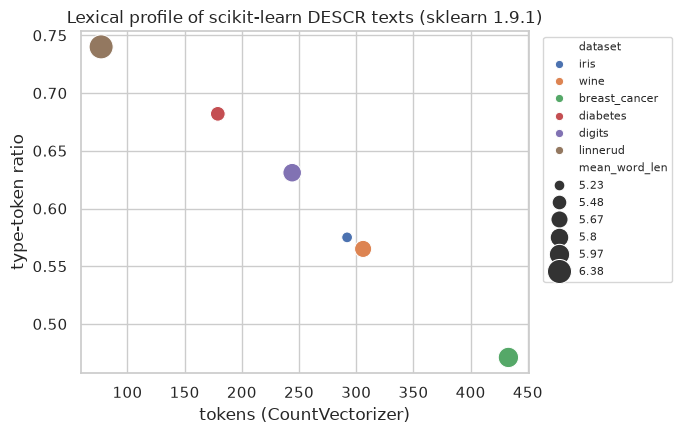

In [32]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=lexical.reset_index(names="dataset"), x="tokens", y="type_token_ratio",
                size="mean_word_len", hue="dataset", sizes=(60, 300), ax=ax)
ax.set(title=f"Lexical profile of scikit-learn DESCR texts (sklearn {sklearn.__version__})",
       xlabel="tokens (CountVectorizer)", ylabel="type-token ratio")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Nota de aprendizado (Linguística):** a razão *type-token* (TTR) cai à medida que o texto cresce — por isso textos longos (`breast_cancer`) parecem "menos ricos". Isso é um artefato conhecido da métrica; em análises reais de materiais didáticos eu usaria medidas normalizadas (MATTR, MTLD). E o resultado acima depende da `token_pattern` e da versão do scikit-learn — mais um motivo para travar o ambiente.

## 11. Checklist final e limpeza

Inventário dos arquivos de ambiente criados nesta sessão — exatamente o que eu versionaria em um projeto real (exceto as pastas de venv).

In [33]:
inventory = pd.DataFrame([
    {"artifact": p.name,
     "kind": "directory" if p.is_dir() else "file",
     "size_bytes": sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) if p.is_dir() else p.stat().st_size,
     "commit_to_git": p.name not in ignored_dirs}
    for p in sorted(WORKDIR.iterdir())
])
inventory

,artifact,kind,size_bytes,commit_to_git
0,.gitignore,file,393,True
1,.venv,directory,94887558,False
2,.venv-uv,directory,94902756,False
3,environment.yml,file,247,True
4,pyproject.toml,file,840,True
5,requirements-dev.txt,file,65,True
6,requirements-edu-nlp.txt,file,749,True
7,requirements-lock.txt,file,166,True
8,requirements.in,file,116,True
9,requirements.txt,file,57,True


In [34]:
# Remove every temporary artifact so the notebook leaves no trace on the machine.
shutil.rmtree(WORKDIR, ignore_errors=True)
print("Workdir removed:", not WORKDIR.exists())

Workdir removed: True


## Resumo do Dia 15

- **Problema:** dependências compartilhadas geram conflitos e resultados não reproduzíveis; a árvore transitiva de `seaborn`/`statsmodels` mostrou quão grande é o risco.
- **`venv`:** criei um ambiente real, inspecionei `pyvenv.cfg` e comprovei o isolamento (`pandas` indisponível no venv novo).
- **`pip` / `pip-tools`:** comandos essenciais, `pip check`, diferença entre `freeze` (snapshot) e `requirements.in` (intenção) + `pip-compile`.
- **`conda`:** `environment.yml`, quando faz sentido (binários não-Python) e como combiná-lo com `pip`.
- **`uv`:** fluxo moderno `uv init/add/lock/sync/run` e `uv.lock` multiplataforma; criei um venv real com `uv venv`.
- **`pyproject.toml`:** dependências, *extras* vs. *dependency groups* (PEP 735), configuração de ferramentas; li o arquivo com `tomllib`.
- **Boas práticas:** `.gitignore`, separação prod/dev, lock verificado por código, fingerprint do ambiente junto com métricas (wine, CV).
- **NLP/educação:** `requirements.txt` comentado por finalidade e uma mini-análise lexical em textos reais do scikit-learn.

**Próximos passos:** migrar um dos meus projetos para `pyproject.toml` + `uv.lock` e adicionar um job de CI que rode `uv sync --frozen` + `pytest`.